# 🌊 Titan-Edge × Planet Tanager — Water Quality & Coastal Intelligence
**Theme:** Water quality, Inland & coastal water intelligence | **Collection:** `coastal-water-bodies`
Goal: turn Tanager hyperspectral indices (NDWI / NDCI / Turbidity) into an early-warning trigger for desalination intakes.

In [1]:
%pip install -q pystac-client planetary-computer stackstac rasterio xarray matplotlib geopandas leafmap ipywidgets rioxarray h5py requests folium branca shapely scipy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.8/41.8 kB 3.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.3/64.3 kB 6.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 669.2/669.2 kB 20.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.4/72.4 kB 6.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 51.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.6/21.6 MB 69.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.0/10.0 MB 94.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.7/7.7 MB 97.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 63.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 108.6/108.6 kB 9.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 96.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 117.3/117.3 kB 11.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 65.

In [2]:
import os, json, warnings
from datetime import datetime, timezone
import numpy as np
import requests
import h5py
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import folium
import branca.colormap as bcm
import leafmap.foliumap as leafmap
from shapely.geometry import box
from IPython.display import Image

warnings.filterwarnings("ignore")
os.environ["TITILER_ENDPOINT"] = "https://titiler.xyz"

## 1️⃣ Scene & AOI — Arabian Gulf / UAE
We prefer scenes that intersect the UAE / Arabian Gulf box below. Set `INTAKE_LATLON` to your real desalination intake to show it on the map.

In [3]:
COLLECTION = "coastal-water-bodies"
item_ids = ["20250511_074311_00_4001", "20250223_165546_32_4001", "20250406_170447_47_4001"]

GULF_UAE_BBOX = [51.0, 22.5, 57.0, 26.5]   # Arabian Gulf + UAE coast (lon/lat)
INTAKE_LATLON = None                        # e.g. (25.17, 56.36) - replace with the real intake

base = f"https://www.planet.com/data/stac/tanager-core-imagery/{COLLECTION}"
items = []
for iid in item_ids:
    r = requests.get(f"{base}/{iid}/{iid}.json", timeout=60)
    r.raise_for_status()
    items.append(r.json())
print(f"Loaded {len(items)} items from {COLLECTION}\n")

gulf = box(*GULF_UAE_BBOX)
for it in items:
    print(it["id"], it["properties"]["datetime"], [round(v, 2) for v in it["bbox"]],
          "| in Gulf/UAE box:", box(*it["bbox"]).intersects(gulf))

hits = [it for it in items if box(*it["bbox"]).intersects(gulf)]
item = hits[0] if hits else items[0]
if not hits:
    print("\n⚠️ No scene intersects the Gulf/UAE box - using the first scene; the 'intake proximity' wording in the alert would not apply.")
print("\nSelected:", item["id"])

Loaded 3 items from coastal-water-bodies

20250511_074311_00_4001 2025-05-11T07:43:11Z [53.63, 23.99, 53.89, 24.19] | in Gulf/UAE box: True
20250223_165546_32_4001 2025-02-23T16:55:46.321891Z [-88.56, 13.14, -88.35, 13.32] | in Gulf/UAE box: False
20250406_170447_47_4001 2025-04-06T17:04:47.473612Z [-91.49, -0.44, -91.27, -0.2] | in Gulf/UAE box: False

Selected: 20250511_074311_00_4001


In [4]:
print("Scene ID:", item["id"])
print("Date    :", item["properties"]["datetime"])
print("Bbox    :", item["bbox"])
Image(url=item["assets"]["thumbnail"]["href"])

Scene ID: 20250511_074311_00_4001
Date    : 2025-05-11T07:43:11Z
Bbox    : [53.63200686177432, 23.990203106931855, 53.89428889725334, 24.192030163555803]


## 2️⃣ Download, Quality Masks, Bands & Indices

In [5]:
sr_key = "ortho_sr_hdf5" if "ortho_sr_hdf5" in item["assets"] else "basic_sr_hdf5"
sr_url = item["assets"][sr_key]["href"]
print("Using SR asset:", sr_key, "\nURL:", sr_url)

local_path = os.path.basename(sr_url)
if not os.path.exists(local_path):
    print("Downloading... (1-5 GB)")
    with requests.get(sr_url, stream=True, timeout=120) as r:
        r.raise_for_status()
        with open(local_path, "wb") as fout:
            for chunk in r.iter_content(chunk_size=1024 * 1024):
                if chunk:
                    fout.write(chunk)
    print("Saved to:", local_path)
else:
    print("Already downloaded:", local_path)

Using SR asset: ortho_sr_hdf5 
URL: https://storage.googleapis.com/open-cogs/planet-stac/tanager1-release2-core-imagery/ortho_sr_hdf5/20250511_074311_00_4001_ortho_sr_hdf5.h5
Downloading... (1-5 GB)
Saved to: 20250511_074311_00_4001_ortho_sr_hdf5.h5


In [6]:
root = "HDFEOS/GRIDS/HYP/Data Fields"
with h5py.File(local_path, "r") as f:
    cloud  = f[f"{root}/beta_cloud_mask"][:]
    nodata = f[f"{root}/nodata_pixels"][:]
    cirrus = f[f"{root}/beta_cirrus_mask"][:]
    sr_shape = f[f"{root}/surface_reflectance"].shape

valid = (nodata == 0) & (cloud == 0) & (cirrus == 0)
print(f"Valid pixels: {valid.mean()*100:.1f}% | Cloud: {(cloud!=0).mean()*100:.1f}% | Cirrus: {(cirrus!=0).mean()*100:.1f}% | NoData: {(nodata!=0).mean()*100:.1f}%")

asset = item["assets"][sr_key]
bands_meta = asset.get("bands") or asset.get("eo:bands") or []
wl = [b.get("eo:center_wavelength", b.get("center_wavelength")) for b in bands_meta]
wavelengths_nm = np.array([w for w in wl if w is not None], dtype=float)
if wavelengths_nm.size and wavelengths_nm.max() < 10:
    wavelengths_nm *= 1000.0      # micrometers -> nanometers
print("Cube shape:", sr_shape, "| wavelengths:", len(wavelengths_nm))
assert sr_shape[0] == len(wavelengths_nm), "Band count != wavelength count"

def pick_band(target_nm):
    idx = int(np.argmin(np.abs(wavelengths_nm - target_nm)))
    print(f"  Target {target_nm} nm -> band {idx} ({wavelengths_nm[idx]:.1f} nm)")
    return idx

print("Selecting bands:")
idx_b443, idx_b560, idx_b665, idx_b708, idx_b800, idx_b860 = [pick_band(t) for t in (443, 560, 665, 708, 800, 860)]

Valid pixels: 38.6% | Cloud: 40.6% | Cirrus: 0.0% | NoData: 20.8%
Cube shape: (426, 733, 878) | wavelengths: 426
Selecting bands:
  Target 443 nm -> band 13 (441.1 nm)
  Target 560 nm -> band 37 (560.8 nm)
  Target 665 nm -> band 58 (665.9 nm)
  Target 708 nm -> band 66 (705.9 nm)
  Target 800 nm -> band 85 (801.1 nm)
  Target 860 nm -> band 97 (861.3 nm)


In [7]:
with h5py.File(local_path, "r") as f:
    sr = f[f"{root}/surface_reflectance"]
    R_443, R_560, R_665, R_708, R_800, R_860 = [
        sr[i, :, :].astype("float32") for i in (idx_b443, idx_b560, idx_b665, idx_b708, idx_b800, idx_b860)]

for arr in [R_443, R_560, R_665, R_708, R_800, R_860]:
    arr[~valid] = np.nan
    arr[arr < 0] = np.nan

eps = 1e-6
NDWI      = (R_560 - R_860) / (R_560 + R_860 + eps)   # water
NDCI      = (R_708 - R_665) / (R_708 + R_665 + eps)   # chlorophyll / HAB proxy
Turbidity = (R_665 - R_560) / (R_665 + R_560 + eps)   # suspended sediment

def summarize(name, arr):
    v = arr[~np.isnan(arr)]
    if len(v) == 0:
        print(f"{name}: no valid data"); return
    print(f"{name}: min={v.min():.3f}  max={v.max():.3f}  mean={v.mean():.3f}  std={v.std():.3f}")

summarize("NDWI", NDWI); summarize("NDCI", NDCI); summarize("Turbidity", Turbidity)

NDWI: min=-0.367  max=0.874  mean=0.636  std=0.232
NDCI: min=-0.276  max=0.249  mean=-0.095  std=0.076
Turbidity: min=-0.605  max=0.184  mean=-0.379  std=0.152


## 📍 Pitch output #2 — 2x2 panel (RGB / NDCI / NDWI / Turbidity)

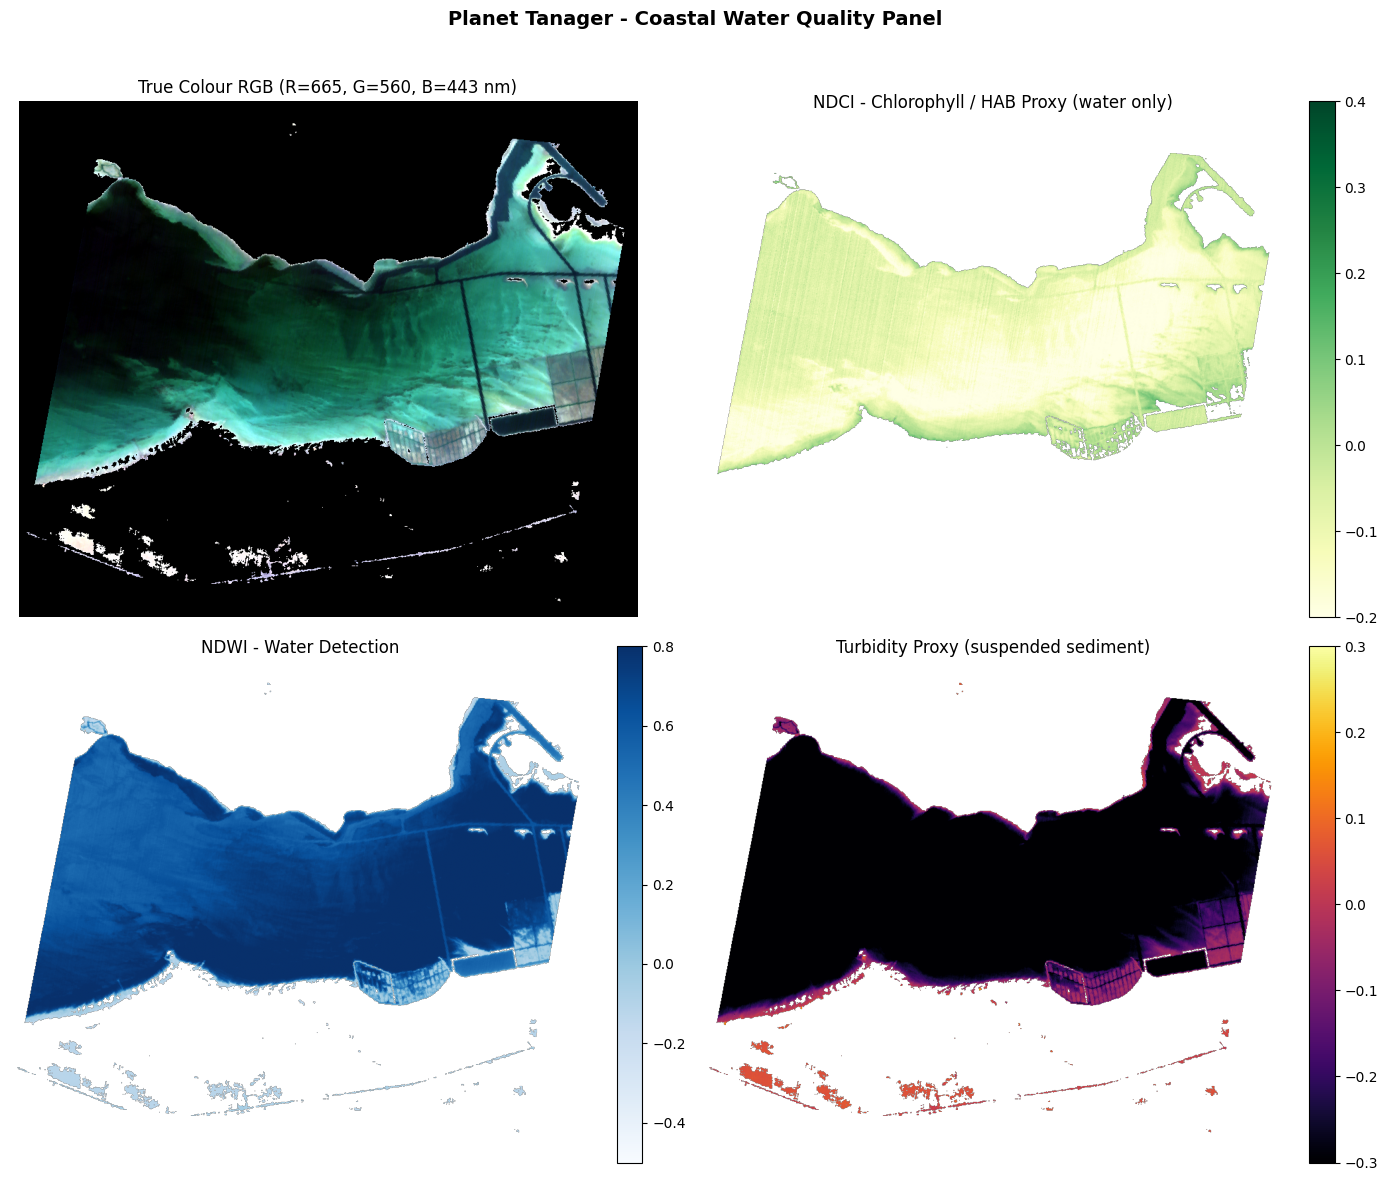

In [8]:
def stretch(arr, p_low=2, p_high=98):
    lo, hi = np.nanpercentile(arr, p_low), np.nanpercentile(arr, p_high)
    return np.clip((arr - lo) / (hi - lo + 1e-6), 0, 1)

rgb_true = np.nan_to_num(np.stack([stretch(R_665), stretch(R_560), stretch(R_443)], axis=-1), nan=0.0)
water_mask = (NDWI > 0.1) & valid
NDCI_water = np.where(water_mask, NDCI, np.nan)

fig, axes = plt.subplots(2, 2, figsize=(14, 12))
axes[0, 0].imshow(rgb_true); axes[0, 0].set_title("True Colour RGB (R=665, G=560, B=443 nm)"); axes[0, 0].axis("off")

im = axes[0, 1].imshow(NDCI_water, cmap="YlGn", vmin=-0.2, vmax=0.4)
axes[0, 1].set_title("NDCI - Chlorophyll / HAB Proxy (water only)"); axes[0, 1].axis("off")
fig.colorbar(im, ax=axes[0, 1], fraction=0.046, pad=0.04)

im = axes[1, 0].imshow(NDWI, cmap="Blues", vmin=-0.5, vmax=0.8)
axes[1, 0].set_title("NDWI - Water Detection"); axes[1, 0].axis("off")
fig.colorbar(im, ax=axes[1, 0], fraction=0.046, pad=0.04)

im = axes[1, 1].imshow(Turbidity, cmap="inferno", vmin=-0.3, vmax=0.3)
axes[1, 1].set_title("Turbidity Proxy (suspended sediment)"); axes[1, 1].axis("off")
fig.colorbar(im, ax=axes[1, 1], fraction=0.046, pad=0.04)

fig.suptitle("Planet Tanager - Coastal Water Quality Panel", fontsize=14, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.96]); plt.show()

## 3️⃣ Spectral Noise Removal & Signature Comparison (Pitch output #3)
Removed: 1350-1450 nm, 1800-1950 nm (water vapor) and > 2450 nm (SWIR detector edge).

Water NDCI: median=-0.101, p99=0.054 | clean px=115480, bloom-candidate px=2310


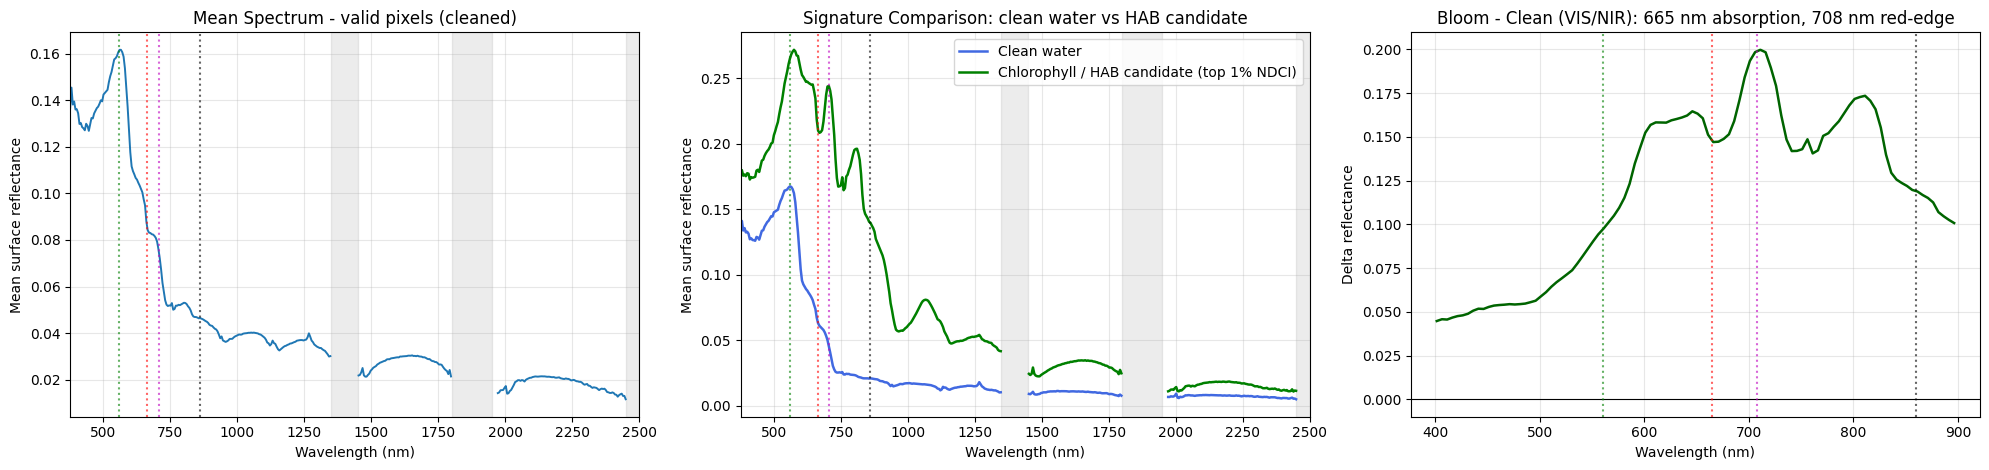

In [9]:
def is_water_vapor(w):
    return (1350 <= w <= 1450) or (1800 <= w <= 1950)

SWIR_EDGE_NM = 2450
def is_bad_band(w):
    return is_water_vapor(w) or w > SWIR_EDGE_NM

bad_bands = np.array([is_bad_band(w) for w in wavelengths_nm])
good_idx = [i for i, b in enumerate(bad_bands) if not b]

stride = 4
with h5py.File(local_path, "r") as f:
    cube = f[f"{root}/surface_reflectance"][:, ::stride, ::stride].astype("float32")
cube[bad_bands] = np.nan       # keep band axis -> plot shows gaps instead of joining lines
cube[cube < 0] = np.nan

def mean_spec(mask):
    m = mask[::stride, ::stride]
    if m.sum() == 0:
        return np.full(cube.shape[0], np.nan)
    return np.nanmean(cube[:, m], axis=1)

# Scene mean (valid pixels)
spec_scene = mean_spec(valid)

# Clean water vs chlorophyll / HAB patch (relative to this scene's water pixels)
assert water_mask.sum() > 0, "No water pixels in this scene"
p50 = np.nanpercentile(NDCI_water, 50)
p99 = np.nanpercentile(NDCI_water, 99)
clean_mask = water_mask & (NDCI <= p50)
bloom_mask = water_mask & (NDCI >= p99)
print(f"Water NDCI: median={p50:.3f}, p99={p99:.3f} | clean px={clean_mask.sum()}, bloom-candidate px={bloom_mask.sum()}")
spec_clean, spec_bloom = mean_spec(clean_mask), mean_spec(bloom_mask)

fig, ax = plt.subplots(1, 3, figsize=(20, 4.8))
ax[0].plot(wavelengths_nm, spec_scene, lw=1.4)
ax[0].set_title("Mean Spectrum - valid pixels (cleaned)")

ax[1].plot(wavelengths_nm, spec_clean, lw=1.8, color="royalblue", label="Clean water")
ax[1].plot(wavelengths_nm, spec_bloom, lw=1.8, color="green", label="Chlorophyll / HAB candidate (top 1% NDCI)")
ax[1].set_title("Signature Comparison: clean water vs HAB candidate"); ax[1].legend()

vis = (wavelengths_nm >= 400) & (wavelengths_nm <= 900)
ax[2].plot(wavelengths_nm[vis], (spec_bloom - spec_clean)[vis], color="darkgreen", lw=1.8)
ax[2].axhline(0, color="k", lw=0.8)
ax[2].set_title("Bloom - Clean (VIS/NIR): 665 nm absorption, 708 nm red-edge")

for a in ax:
    for lo, hi in [(1350, 1450), (1800, 1950), (SWIR_EDGE_NM, 2500)]:
        if a is not ax[2]:
            a.axvspan(lo, hi, color="grey", alpha=0.15)
    for t, c in [(560, "g"), (665, "r"), (708, "m"), (860, "k")]:
        a.axvline(t, color=c, ls=":", alpha=0.6)
    a.set_xlabel("Wavelength (nm)"); a.grid(alpha=0.3)
ax[0].set_ylabel("Mean surface reflectance"); ax[1].set_ylabel("Mean surface reflectance"); ax[2].set_ylabel("Delta reflectance")
ax[0].set_xlim(wavelengths_nm.min(), 2500); ax[1].set_xlim(wavelengths_nm.min(), 2500)
plt.tight_layout(); plt.show()

## 🗺️ Pitch output #1 — Interactive map with the water body and NDCI hotspot
The scene is placed using its STAC bbox (north-up ortho product), so overlay positions are approximate.

Saved: titan_edge_tanager_map.html



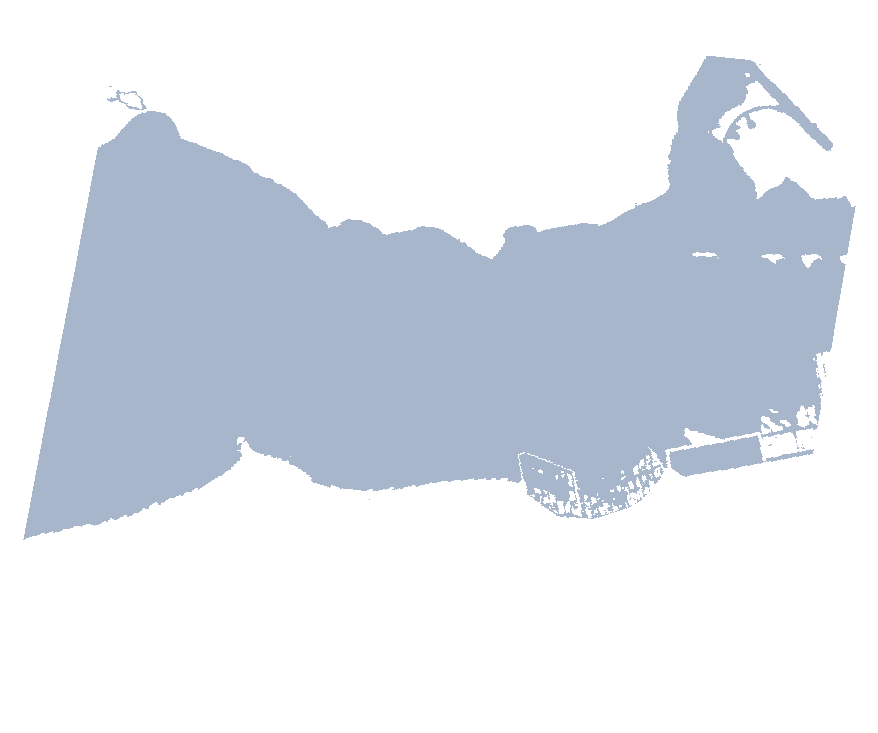
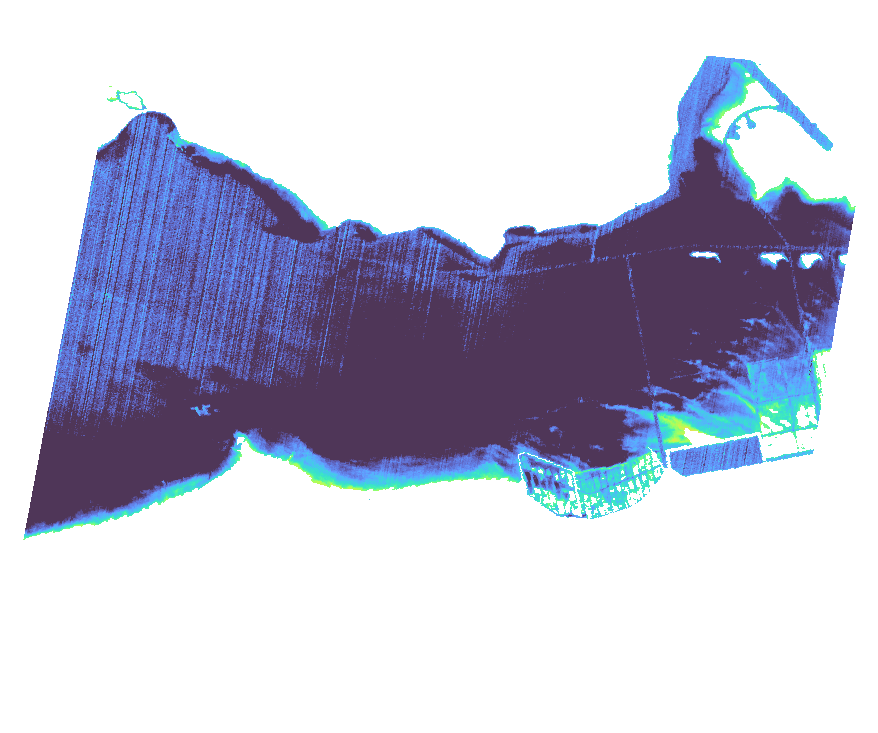

In [10]:
ib = item["bbox"]   # [minx, miny, maxx, maxy]
H, W = NDCI.shape

def to_rgba(a, vmin, vmax, cmap, alpha=0.85):
    norm = np.clip((a - vmin) / (vmax - vmin), 0, 1)
    rgba = plt.get_cmap(cmap)(np.nan_to_num(norm))
    rgba[..., 3] = np.where(np.isfinite(a), alpha, 0.0)
    return (rgba * 255).astype(np.uint8)

m = leafmap.Map(center=[(ib[1] + ib[3]) / 2, (ib[0] + ib[2]) / 2], zoom=8)
m.add_basemap("SATELLITE")
bounds = [[ib[1], ib[0]], [ib[3], ib[2]]]

# Water body mask (blue) and NDCI over water
folium.raster_layers.ImageOverlay(
    image=to_rgba(np.where(water_mask, 1.0, np.nan), 0, 1, "Blues", 0.35),
    bounds=bounds, origin="upper", name="Water mask (NDWI > 0.1)").add_to(m)
folium.raster_layers.ImageOverlay(
    image=to_rgba(NDCI_water, -0.1, 0.3, "turbo"),
    bounds=bounds, origin="upper", name="NDCI (water)").add_to(m)

folium.Rectangle(bounds, color="yellow", weight=2, fill=False, name="Scene footprint").add_to(m)

# Peak NDCI pixel (approximate lat/lon from bbox)
if np.isfinite(NDCI_water).any():
    r, c = np.unravel_index(np.nanargmax(NDCI_water), NDCI_water.shape)
    lat = ib[3] - (r + 0.5) / H * (ib[3] - ib[1])
    lon = ib[0] + (c + 0.5) / W * (ib[2] - ib[0])
    folium.CircleMarker([lat, lon], radius=8, color="red", fill=True,
                        tooltip=f"Peak NDCI = {np.nanmax(NDCI_water):.3f} (approx. location)").add_to(m)

if INTAKE_LATLON:
    folium.Marker(INTAKE_LATLON, tooltip="Desalination intake",
                  icon=folium.Icon(color="blue", icon="tint", prefix="fa")).add_to(m)

bcm.LinearColormap([mcolors.to_hex(plt.get_cmap("turbo")(v)) for v in np.linspace(0, 1, 8)],
                   vmin=-0.1, vmax=0.3, caption="NDCI").add_to(m)
folium.LayerControl().add_to(m)
m.save("titan_edge_tanager_map.html")
print("Saved: titan_edge_tanager_map.html")
m

## 4️⃣ Titan-Edge Decision & Trigger Kernel (Pitch output #4)
NDCI is treated as a **spectral proxy / indicator, not ground truth**. To limit false positives the alert needs a **spatial cluster** (>= `MIN_CLUSTER_PIXELS` connected water pixels above the NDCI threshold), and the result is labelled **Suspected HAB Anomaly** - pending field verification by the Falcon Eye UAV.

In [11]:
# Titan-Edge Decision & Trigger Kernel
import numpy as np
from scipy import ndimage

# ---- Configuration ----
NDCI_THRESHOLD     = 0.20   # proxy threshold (calibrate with in-situ data)
MIN_CLUSTER_PIXELS = 8      # minimum connected pixels (suggested range: 5-10)
PIXEL_SIZE_M       = 30.0   # Tanager nominal ground sampling distance (m) - override if your product differs

water_mask = (NDWI > 0.1) & valid
max_ndci_val  = float(np.nanmax(NDCI[water_mask])) if np.any(water_mask) else 0.0
mean_turb_val = float(np.nanmean(Turbidity[water_mask])) if np.any(water_mask) else 0.0

# ---- Spatial clustering (8-connectivity) of water pixels above threshold ----
hot = water_mask & np.isfinite(NDCI) & (NDCI >= NDCI_THRESHOLD)
labels, n_clusters = ndimage.label(hot, structure=np.ones((3, 3), dtype=int))
sizes = np.bincount(labels.ravel())[1:] if n_clusters > 0 else np.array([], dtype=int)

keep_ids = np.where(sizes >= MIN_CLUSTER_PIXELS)[0] + 1          # label ids of qualifying clusters
anomaly = keep_ids.size > 0
isolated_px = int(sizes[sizes < MIN_CLUSTER_PIXELS].sum()) if sizes.size else 0
affected_px = int(sizes[keep_ids - 1].sum()) if anomaly else 0
largest_px  = int(sizes.max()) if sizes.size else 0
pixel_area_m2 = PIXEL_SIZE_M ** 2
affected_area_m2 = affected_px * pixel_area_m2

# Sanity check of pixel size using the scene footprint (rough: bbox of the footprint)
ib = item["bbox"]; Hh, Ww = NDCI.shape
lat_c = (ib[1] + ib[3]) / 2
est_px_x = (ib[2] - ib[0]) * 111320 * np.cos(np.radians(lat_c)) / Ww
est_px_y = (ib[3] - ib[1]) * 110574 / Hh
print(f"(pixel size check: nominal {PIXEL_SIZE_M:.0f} m | bbox-derived ~{est_px_x:.0f} x {est_px_y:.0f} m)\n")

print(f"🌐 [SATELLITE SPECTRUM EVALUATION - PLANET TANAGER]")
print(f" ├─ Peak NDCI (Chlorophyll proxy): {max_ndci_val:.4f}")
print(f" ├─ Mean Water Turbidity (proxy) : {mean_turb_val:.4f}")
print(f" ├─ Pixels >= {NDCI_THRESHOLD:.2f}: {int(hot.sum())} in {n_clusters} cluster(s) | largest = {largest_px} px")
print(f" └─ Qualifying clusters (>= {MIN_CLUSTER_PIXELS} px): {keep_ids.size} | affected area ~ {affected_area_m2:,.0f} m2\n")

if anomaly:
    print("🚨 [TITAN-EDGE ALERT]: Suspected HAB Anomaly - spatial cluster with elevated Red-Edge chlorophyll proxy (NDCI, 708/665 nm)!")
    print("🛰️ Target Location: Coastal Marine Zone / Desalination Intake Proximity")
    print("🚁 [TITAN-AIR TRIGGER]: Launching Falcon Eye UAV for localized micro-sampling (ground-truth verification).")
    print("🛡️ [TITAN-POWER ACTION]: Sending low-power off-grid RF signal to secure intake barriers (precautionary).")
else:
    if hot.any():
        print(f"ℹ️ [TITAN-EDGE NOTE]: {isolated_px} high-NDCI pixel(s) found but no cluster >= {MIN_CLUSTER_PIXELS} px - treated as noise / isolated outliers (no trigger).")
    print("✅ [TITAN-EDGE STATUS]: Marine environment within safe operating limits. Edge nodes on standby.")

(pixel size check: nominal 30 m | bbox-derived ~30 x 30 m)

🌐 [SATELLITE SPECTRUM EVALUATION - PLANET TANAGER]
 ├─ Peak NDCI (Chlorophyll proxy): 0.1439
 ├─ Mean Water Turbidity (proxy) : -0.4071
 ├─ Pixels >= 0.20: 0 in 0 cluster(s) | largest = 0 px
 └─ Qualifying clusters (>= 8 px): 0 | affected area ~ 0 m2

✅ [TITAN-EDGE STATUS]: Marine environment within safe operating limits. Edge nodes on standby.


In [12]:
# Machine-readable event log (dashboard / REST / MQTT)
event = {
    "timestamp_utc": datetime.now(timezone.utc).isoformat(),
    "scene_id": item["id"], "scene_datetime": item["properties"]["datetime"], "bbox": item["bbox"],
    "anomaly_status": "SUSPECTED" if anomaly else "NONE",
    "indicator": "NDCI (spectral proxy, not ground truth)",
    "ndci_threshold": NDCI_THRESHOLD,
    "ndci_max": max_ndci_val,
    "mean_turbidity_proxy": mean_turb_val,
    "min_cluster_pixels": MIN_CLUSTER_PIXELS,
    "clusters_total": int(n_clusters),
    "clusters_qualifying": int(keep_ids.size),
    "affected_pixels": affected_px,
    "largest_cluster_pixels": largest_px,
    "pixel_size_m": PIXEL_SIZE_M,
    "affected_area_m2": float(affected_area_m2),
    "isolated_pixels_ignored": isolated_px,
    "next_action": "UAV field sampling for ground-truth verification" if anomaly else "standby",
}
print(json.dumps(event, indent=2, ensure_ascii=False))

{
  "timestamp_utc": "2026-10-08T08:28:13.323414+00:00",
  "scene_id": "20250511_074311_00_4001",
  "scene_datetime": "2025-05-11T07:43:11Z",
  "bbox": [
    53.63200686177432,
    23.990203106931855,
    53.89428889725334,
    24.192030163555803
  ],
  "anomaly_status": "NONE",
  "indicator": "NDCI (spectral proxy, not ground truth)",
  "ndci_threshold": 0.2,
  "ndci_max": 0.14386840164661407,
  "mean_turbidity_proxy": -0.40705743432044983,
  "min_cluster_pixels": 8,
  "clusters_total": 0,
  "clusters_qualifying": 0,
  "affected_pixels": 0,
  "largest_cluster_pixels": 0,
  "pixel_size_m": 30.0,
  "affected_area_m2": 0.0,
  "isolated_pixels_ignored": 0,
  "next_action": "standby"
}


In [13]:
%pip install "hypercoast[extra]"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 78.7/78.7 kB 7.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 180.6/180.6 kB 15.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 178.1/178.1 kB 15.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 33.7/33.7 MB 32.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.1/10.1 MB 70.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 102.6/102.6 kB 4.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 221.7/221.7 kB 15.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 42.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 48.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 261.4/261.4 kB 15.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 319.7/319.7 kB 14.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.0/16.0 MB 31.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 28

## 🔬 Interactive Hyperspectral Explorer (HyperCoast)
Click any pixel to plot its full spectral signature (e.g. compare a clean-water pixel with a suspected bloom pixel).

In [14]:
import hypercoast

# Read the Tanager surface-reflectance HDF5 downloaded above (wavelengths already extracted from STAC)
ds = hypercoast.read_tanager(local_path, wavelengths=wavelengths_nm)

m = hypercoast.Map()
m.add_tanager(
    ds,
    wavelengths=[665, 560, 443],      # true-colour RGB (R, G, B)
    vmin=0, vmax=0.2,                 # surface reflectance stretch
    layer_name="Tanager RGB (665/560/443 nm)",
)
m.add("spectral")                      # click any pixel to plot its spectral signature
m

Map(center=[24.09101, 53.763042999999996], controls=(ZoomControl(options=['position', 'zoom_in_text', 'zoom_in…

## 📊 Before You Submit
Validate NDCI against in-situ chlorophyll-a or a documented HAB event (precision/recall, RMSE), calibrate the 0.20 threshold and the minimum cluster size, and consider requiring repeat detection across acquisitions before dispatching assets.

In [17]:
import json, zipfile, glob, os
from google.colab import files

json.dump(event, open("titan_edge_event.json", "w"), indent=2, ensure_ascii=False)

os.makedirs("s2_fujairah", exist_ok=True)
 for n, a in zip(["B03", "B04", "B05", "B08"], [r03, r04, r05, r08]):
    a.rio.write_crs(f"EPSG:{UTM_EPSG}").rio.to_raster(f"s2_fujairah/S2_{n}.tif")
dts = sorted(i.datetime for i in s2_items)
json.dump({"source": "Sentinel-2 L2A", "bbox": bbox,
           "datetime": dts[len(dts) // 2].strftime("%Y-%m-%dT%H:%M:%SZ")},
          open("s2_fujairah/meta.json", "w"))

with zipfile.ZipFile("titan_results.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for f in (["titan_edge_hab_map.html", "titan_edge_event.json"]
              + glob.glob("s2_fujairah/*") + glob.glob("*.png")):
        z.write(f)
files.download("titan_results.zip")

IndentationError: unexpected indent (2866374604.py, line 7)